# Roadster task 1 — validating the tire-only launch

Issue #64 asks whether the 2026 Tesla Roadster can do 0–60 mph in under one second on its tires
alone. Task 1 of `docs/roadster-dyad-tasks.md` hands over a draft model for that question and asks
for it to be checked rather than trusted. This notebook is that check: it runs the draft,
recomputes every closed form from its formula, measures every row of the acceptance table, and
states a verdict on each item the brief asks to be reviewed.

Nothing under `dyad/`, `generated/` or `test/` was changed to produce this notebook. Where the
check found a problem, it is documented here, not fixed.

**Findings in one paragraph.** Every acceptance row passes: all-wheel drive reaches 60 mph in
about 2.27 s and rear-wheel drive in about 3.33 s, so the claim of under one second on tires
fails by a factor of two to three, and the tire, not the 1 MW drive, is the limit at 60 mph. The
gap between the closed forms and the model is fully accounted for by drag, rolling resistance,
wheel inertia and the pitch lag: remove those four and the model reproduces the closed form to
the fourth digit. One modeling problem was found. The traction control is open loop on `F_z`, so
nothing pulls the tire back once it passes its adhesion peak. At the solver's default tolerances
the wheel jumps the peak in the first 0.1 ms, spins up for the whole run, and the same model
reports a 4.27 s launch. The shipped analysis is correct only because it pins tight tolerances.
A second, smaller one: the traction control does not supply the torque that spins the wheel up,
so wheel inertia comes straight off the tire force, and a plausible reflected rotor inertia
pushes rear-wheel drive out of its band.

## Setup

The notebook activates the repository's own project. `Plots` is not a dependency of the package;
it loads from the Dyad distribution's bundled standard library, so nothing is added to
`Project.toml`. `show_dyad` comes from the lecture 1 `support.jl`, which lifts a declaration out
of `dyad/` with its docstring. The first analysis call compiles the model, which takes about half
a minute on a cold start.

In [1]:
using Pkg
Pkg.activate(normpath(pwd(), "..", ".."); io = devnull)

using VehicleSystemsComponents, DyadInterface, ModelingToolkit, SciMLBase, Plots
using Markdown, Printf

isdefined(Main, :Lecture01Support) || include(joinpath("..", "lecture01", "support.jl"))
const show_dyad = Lecture01Support.show_dyad

gr()
default(size = (900, 420), left_margin = 6Plots.mm, bottom_margin = 6Plots.mm,
    right_margin = 4Plots.mm, legendfontsize = 8, titlefontsize = 11, lw = 2)

Small helpers, written here rather than borrowed from `test/roadster_plausibility.jl`, so that
this check does not inherit a mistake from the tests it is checking.

- `launch` runs the analysis and returns its solution with the compiled model, read exactly as
  the brief prescribes: `result.sol` and `DyadInterface.symbolic_container(result)`.
- `rerun` re-solves the same compiled problem with parameters changed through `remake`. It
  passes the analysis's own tolerances explicitly, for a reason section 8 makes clear.
- `t60` bisects the solver's dense interpolant for the moment `v` crosses 26.8224 m/s, rather
  than interpolating linearly between saved points. Speed rises monotonically, so bisection is
  safe.
- `binding_limit` evaluates the three torque ceilings the motor takes the minimum of, and names
  the smallest.

In [2]:
const V60 = 26.8224                         # 60 mph in m/s
const g = 9.80665
const TOL = (abstol = 1e-8, reltol = 1e-6)  # RoadsterLaunchTransient's own tolerances

function launch(; kw...)
    result = VehicleSystemsComponents.Roadster.RoadsterLaunchTransient(; kw...)
    return (sol = result.sol, model = DyadInterface.symbolic_container(result))
end

function rerun(run, overrides::Pair...; tol = TOL)
    prob = isempty(overrides) ? run.sol.prob : remake(run.sol.prob; p = collect(overrides))
    return (sol = solve(prob; tol...), model = run.model)
end

at(run, x, t) = run.sol(t; idxs = x)
trace(run, x, ts) = [at(run, x, t) for t in ts]
param(run, p) = run.sol.prob.ps[p]

function crossing(run, x, level)
    lo, hi = 0.0, run.sol.t[end]
    at(run, x, hi) < level && return Inf
    for _ in 1:60
        mid = (lo + hi) / 2
        at(run, x, mid) < level ? (lo = mid) : (hi = mid)
    end
    return (lo + hi) / 2
end
t60(run) = crossing(run, run.model.v, V60)

function binding_limit(run, t)
    m = run.model
    ceilings = (tire = at(run, m.motor.tau_cmd, t),
                torque = param(run, m.motor.T_max),
                power = param(run, m.motor.P_max) / max(at(run, m.motor.w, t), param(run, m.motor.w_eps)))
    names, levels = collect(keys(ceilings)), collect(values(ceilings))
    order = sortperm(levels)
    return (limit = names[order[1]], next = names[order[2]], margin = levels[order[2]] / levels[order[1]] - 1, ceilings)
end

peak_g(run, T) = maximum(trace(run, run.model.axle.a, range(0, T, length = 2000))) / g

fmt(x; d = 3) = Printf.format(Printf.Format("%.$(d)f"), x)
mdtable(header, rows) = Markdown.parse(join(vcat(
    "| " * join(header, " | ") * " |",
    "|" * repeat(":--- |", length(header)),
    ["| " * join(r, " | ") * " |" for r in rows]), "\n"))

mdtable (generic function with 1 method)

## 1. The models under test

### The drive: `PowerLimitedMotor`

One torque source referred to the wheels. It delivers the commanded torque up to the torque
ceiling `T_max`, and never more than `P_max / w`. The `max(w, w_eps)` keeps the power ceiling
finite at standstill. It extends the standard library's `PartialTorque`, so its torque sign is
`tau = -spline.tau`, the same as `RotationalComponents.Sources.ConstantTorque`.

In [3]:
show_dyad("PowerLimitedMotor")

**`PowerLimitedMotor`** — [`dyad/Roadster/PowerLimitedMotor.dyad`](../../dyad/Roadster/PowerLimitedMotor.dyad) line 1

```julia
"""
Electric drive referred to the driven wheels: it delivers the commanded torque up to a torque
ceiling, and above base speed no more than its rated power allows.

The torque ceiling and the power ceiling meet at base speed `P_max / T_max`. Below it the drive
is torque-limited, above it the available torque falls as `P_max / w`. `w_eps` keeps the power
ceiling finite at standstill. This reduced-order source models forward traction only; it does not
represent reverse drive or regenerative braking.
"""
component PowerLimitedMotor
  extends RotationalComponents.Interfaces.PartialTorque
  "Requested wheel torque"
  tau_cmd = RealInput() {^tau_cmd}
  "Peak wheel torque; 1,400 N.m at the motor times an assumed 8.5:1 reduction"
  parameter T_max::Torque = 12000
  "Rated power; press reports describe the drive as over 1 MW"
  parameter P_max::Power = 1.0e6
  "Speed floor for the power ceiling; numerical regularization"
  parameter w_eps::AngularVelocity = 1.0
  "Wheel speed"
  variable w::AngularVelocity
  "Delivered wheel torque"
  variable tau::Torque
  "Delivered mechanical power"
  variable P::Power
relations
  w = der(phi)
  tau = -spline.tau
  tau = min(min(tau_cmd, T_max), P_max / max(w, w_eps))
  P = tau * w
end
```


### The load on the driven axle: `AxleLoad`

    F_z = share·(m·g + downforce) + m·a_pitch·h/L,       T_pitch·da_pitch/dt = a − a_pitch

A pure sensor on the body flange (`flange.f = 0`): it reads the body's acceleration and reports
the normal load. Under acceleration, load moves rearward, so the rear axle gains `m·a·h/L`.
All-wheel drive is `share = 1`, `h_over_L = 0`, because transfer then only moves load between
driven wheels. The lag `a_pitch` stands in for the time the body takes to pitch.

In [4]:
show_dyad("AxleLoad")

**`AxleLoad`** — [`dyad/Roadster/AxleLoad.dyad`](../../dyad/Roadster/AxleLoad.dyad) line 1

```julia
"""
Normal load on the driven axle during straight-line acceleration.

The driven axle carries `share` of the weight and of the downforce at rest. Acceleration
`a` moves `m * a * h / L` onto the rear axle, which is the term that limits a rear-wheel-drive
launch. All-wheel drive is `share = 1` with `h_over_L = 0`: weight transfer only moves load
between driven wheels.

The transfer follows the acceleration through a first-order lag of `T_pitch`, the time the
suspension takes to pitch the body. The lag also keeps the solver from solving the load equation
for the acceleration, which would divide by `h_over_L`.
"""
component AxleLoad
  "Connection to the vehicle body, used to measure its acceleration"
  flange = Flange() {^flange}
  "Downforce, as a force pushing the car onto the road"
  downforce = RealInput() {^downforce}
  "Normal load on the driven axle"
  F_z = RealOutput() {^F_z}
  "Vehicle mass; assumed because Tesla has not disclosed it"
  parameter m::Dyad.Mass = 2000
  "Static fraction of weight and downforce on the driven axle; assumed"
  parameter share::Real = 0.55
  "Center-of-mass height over wheelbase; assumed"
  parameter h_over_L::Real = 0.17
  "Reduced-order suspension pitch time constant; assumed"
  parameter T_pitch::Time = 0.1
  "Standard gravitational acceleration"
  parameter g::Acceleration = 9.80665
  "Vehicle speed"
  variable v::Velocity
  "Vehicle acceleration"
  variable a::Acceleration
  "Acceleration seen by the suspension"
  variable a_pitch::Acceleration
relations
  v = der(flange.s)
  a = der(v)
  flange.f = 0
  T_pitch * der(a_pitch) = a - a_pitch
  F_z = share * (m * g + downforce) + m * a_pitch * h_over_L
metadata {
  "_links": {
    "flange": {
      "Dyad": {"placement": {"diagram": {"x1": -50, "x2": 50, "y1": 450, "y2": 550}}}
    },
    "downforce": {
      "Dyad": {"placement": {"diagram": {"x1": 450, "x2": 550, "y1": -50, "y2": 50}}}
    },
    "F_z": {
      "Dyad": {"placement": {"diagram": {"x1": 950, "x2": 1050, "y1": 450, "y2": 550}}}
    }
  }
}
end
```


### The tire: `LoadedSlipWheel1D` and its friction curve

`SlipWheel1D` with the normal load as an input signal. The slip ratio is
`kappa = (omega·r − v) / max(|v|, v_eps)` and the tire force is `F_x = mu(kappa)·F_z`. The curve
rises to `mu_A` at `kappa = sAdhesion = 0.04`, falls to `mu_S` at `sSlide = 0.12`, and stays
there. Past the peak the curve slopes down, and that branch is unstable: more slip gives less
force, so a wheel driven by a torque above `mu_S·F_z·r` keeps spinning up. Section 8 depends on
this.

In [5]:
show_dyad("LoadedSlipWheel1D")

**`LoadedSlipWheel1D`** — [`dyad/Vehicle/Wheel/LoadedSlipWheel1D.dyad`](../../dyad/Vehicle/Wheel/LoadedSlipWheel1D.dyad) line 1

```julia
"""
One-dimensional tire contact whose normal load is a signal rather than a constant.

Same slip definition, sign conventions and friction curve as `SlipWheel1D`. The normal load
`F_z` arrives at an input, so weight transfer and aerodynamic or suction downforce can change the
grip the tire offers while the vehicle moves.
"""
component LoadedSlipWheel1D
  "Wheel shaft"
  spline = Spline() {^spline}
  "Longitudinal connection to the vehicle body"
  flange = Flange() {^flange}
  "Normal load on the tire"
  F_z = RealInput() {^F_z}
  "Friction coefficient against slip"
  curve = VehicleSystemsComponents.Vehicle.Wheel.TireFrictionCurve(sAdhesion = sAdhesion, sSlide = sSlide, mu_A = mu_A, mu_S = mu_S) {^curve}
  "Wheel rolling radius; assumed"
  parameter radius::Length = 0.35
  "Slip ratio at peak adhesion; assumed from the reusable tire curve"
  parameter sAdhesion::Real = 0.04
  "Slip ratio at the sliding plateau; assumed from the reusable tire curve"
  parameter sSlide::Real = 0.12
  "Peak adhesion coefficient; Tesla's stated tire limit"
  parameter mu_A::Real = 1.26
  "Sliding friction coefficient; assumed"
  parameter mu_S::Real = 1.0
  "Low-speed denominator floor that avoids singular standstill slip; numerical regularization"
  parameter v_eps::Velocity = 0.5
  "Wheel angular speed"
  variable omega::AngularVelocity
  "Vehicle longitudinal speed"
  variable v::Velocity
  "Regularized longitudinal slip ratio"
  variable kappa::Real
  "Longitudinal tire force"
  variable F_x::Force
relations
  omega = der(spline.phi)
  v = der(flange.s)
  kappa = (omega * radius - v) / max(abs(v), v_eps)
  curve.kappa = kappa
  F_x = curve.mu * F_z
  # Flow is positive into this component, so traction on the body appears as a negative flange force.
  flange.f = -F_x
  0 = spline.tau + radius * flange.f
metadata {
  "_links": {
    "spline": {
      "Dyad": {"placement": {"diagram": {"x1": -40, "x2": 60, "y1": 440, "y2": 540}}}
    },
    "flange": {
      "Dyad": {"placement": {"diagram": {"x1": 960, "x2": 1060, "y1": 450, "y2": 550}}}
    },
    "F_z": {
      "Dyad": {"placement": {"diagram": {"x1": 460, "x2": 560, "y1": -50, "y2": 50}}}
    },
    "curve": {
      "Dyad": {"placement": {"diagram": {"x1": 450, "x2": 550, "y1": 450, "y2": 550}}}
    }
  }
}
end
```


In [6]:
show_dyad("TireFrictionCurve")

**`TireFrictionCurve`** — [`dyad/HandsOn/TireFrictionCurve.dyad`](../../dyad/HandsOn/TireFrictionCurve.dyad) line 1

```julia
"""
Tire friction coefficient against longitudinal slip: rises to the adhesion peak `mu_A` at
`sAdhesion`, falls to the sliding level `mu_S` at `sSlide`, and stays there. Point-symmetric, so
braking slip gives negative friction.
"""
component TireFrictionCurve
  "Longitudinal slip ratio, negative while braking"
  kappa = RealInput() {^kappa}
  "Friction coefficient, carrying the sign of the slip"
  mu = RealOutput() {^mu}
  "Slip ratio at peak adhesion"
  parameter sAdhesion::Real = 0.04
  "Slip ratio at the sliding plateau"
  parameter sSlide::Real = 0.12
  "Peak adhesion coefficient"
  parameter mu_A::Real = 1.0
  "Sliding friction coefficient"
  parameter mu_S::Real = 0.7
  "Slip magnitude"
  variable slip::Real
  "Friction magnitude"
  variable mu_abs::Real
relations
  slip = abs(kappa)
  # -0.5·x³ + 1.5·x maps [-1, 1] onto [-1, 1] with zero slope at both ends, so the curve stays
  # continuously differentiable across the segment joins.
  mu_abs = ifelse(slip <= sAdhesion,
    mu_A * (-0.5 * (slip / sAdhesion) ^ 3 + 1.5 * (slip / sAdhesion)),
    ifelse(slip >= sSlide, mu_S,
      (mu_A + mu_S) / 2 + (mu_S - mu_A) / 2 * (-0.5 * ((slip - (sAdhesion + sSlide) / 2) * 2 / (sSlide - sAdhesion)) ^ 3 + 1.5 * ((slip - (sAdhesion + sSlide) / 2) * 2 / (sSlide - sAdhesion)))))
  mu = sign(kappa) * mu_abs
metadata {
  "Dyad": {
    "icons": {"default": "dyad://VehicleSystemsComponents/HandsOn/TireFrictionCurve.svg"},
    "labels": [{"label": "$(instance)", "x": 500, "y": 1100, "rot": 0}]
  },
  "_links": {
    "kappa": {
      "Dyad": {"placement": {"diagram": {"x1": -50, "x2": 50, "y1": 450, "y2": 550}}}
    },
    "mu": {
      "Dyad": {"placement": {"diagram": {"x1": 950, "x2": 1050, "y1": 450, "y2": 550}}}
    }
  }
}
end
```


### The launch: `RoadsterLaunch` and its analysis

Motor → wheel inertia `J_w` → tire → body (`VehicleSystemsComponents.Vehicle.VehicleBody`, with
drag `½ρ·CdA·v²` and rolling resistance `f_r·m·g`, link:
[`dyad/Vehicle/VehicleBody.dyad`](../../dyad/Vehicle/VehicleBody.dyad)). The axle load feeds the
tire's `F_z` and also the traction control, a gain of `grip·mu_A·radius` that turns `F_z` into a
torque request. It is "ideal traction control" because it knows the load exactly; it does not
look at slip at all.

In [7]:
show_dyad("RoadsterLaunch")

**`RoadsterLaunch`** — [`dyad/Roadster/RoadsterLaunch.dyad`](../../dyad/Roadster/RoadsterLaunch.dyad) line 1

```julia
"""
Standing-start launch of a 1 MW car on its tires alone, with ideal traction control.

The traction control requests the torque that holds the tire just below peak adhesion,
`grip * mu_A * F_z * radius`, and the motor delivers it up to its torque and power ceilings.
The run answers whether 0–60 mph (26.82 m/s) in under one second is possible on tires: it is
limited by `mu_A * g` for all-wheel drive and by weight transfer for rear-wheel drive.
"""
component RoadsterLaunch
  motor = VehicleSystemsComponents.Roadster.PowerLimitedMotor(T_max = T_max, P_max = P_max) {^motor}
  wheel_inertia = RotationalComponents.Components.Inertia(J = J_w) {^wheel_inertia}
  wheel = VehicleSystemsComponents.Vehicle.Wheel.LoadedSlipWheel1D(radius = radius, mu_A = mu_A, mu_S = mu_S) {^wheel}
  body = VehicleSystemsComponents.Vehicle.VehicleBody(m = m, CdA = CdA) {^body}
  axle = VehicleSystemsComponents.Roadster.AxleLoad(m = m, share = share, h_over_L = h_over_L) {^axle}
  traction = BlockComponents.Math.Gain(k = grip * mu_A * radius) {^traction}
  no_downforce = BlockComponents.Sources.Constant(k = 0) {^no_downforce}
  flat = BlockComponents.Sources.Constant(k = 0) {^flat}
  "Motor housing"
  rot_ground = RotationalComponents.Components.Fixed() {^rot_ground}
  "Vehicle mass; assumed because Tesla has not disclosed it"
  parameter m::Dyad.Mass = 2000
  "Aerodynamic drag area, Cd * A; assumed"
  parameter CdA::Area = 0.6
  "Peak wheel torque; 1,400 N.m at the motor times an assumed 8.5:1 reduction"
  parameter T_max::Torque = 12000
  "Rated power; press reports describe the drive as over 1 MW"
  parameter P_max::Power = 1.0e6
  "Combined inertia of the driven wheels; assumed"
  parameter J_w::MomentOfInertia = 2.4
  "Wheel rolling radius; assumed"
  parameter radius::Length = 0.35
  "Peak tire adhesion; Tesla's stated tire limit"
  parameter mu_A::Real = 1.26
  "Sliding tire friction; assumed"
  parameter mu_S::Real = 1.0
  "Fraction of peak adhesion targeted by ideal traction control; assumed margin"
  parameter grip::Real = 0.98
  "Static fraction of weight on the driven axle; assumed"
  parameter share::Real = 0.55
  "Center-of-mass height over wheelbase; assumed"
  parameter h_over_L::Real = 0.17
  "Vehicle speed"
  variable v::Velocity
relations
  connect(motor.spline, wheel_inertia.spline_a) {^id1}
  connect(motor.support, rot_ground.spline) {^id2}
  connect(wheel_inertia.spline_b, wheel.spline) {^id3}
  connect(wheel.flange, body.flange) {^id4}
  connect(axle.flange, body.flange) {^id5}
  connect(no_downforce.y, axle.downforce) {^id6}
  connect(axle.F_z, wheel.F_z) {^id7}
  connect(axle.F_z, traction.u) {^id8}
  connect(traction.y, motor.tau_cmd) {^id9}
  connect(flat.y, body.grade) {^id10}
  v = axle.v
  initial wheel_inertia.phi = 0.0
  initial wheel_inertia.w = 0.0
  initial body.mass.s = 0.0
  initial body.mass.v = 0.0
  initial axle.a_pitch = 0.0
metadata {
  "_links": {
    "motor": {"Dyad": {"placement": {"diagram": {"x1": 100, "x2": 200, "y1": 450, "y2": 550}}}},
    "wheel_inertia": {
      "Dyad": {"placement": {"diagram": {"x1": 300, "x2": 400, "y1": 450, "y2": 550}}}
    },
    "wheel": {"Dyad": {"placement": {"diagram": {"x1": 500, "x2": 600, "y1": 450, "y2": 550}}}},
    "body": {"Dyad": {"placement": {"diagram": {"x1": 750, "x2": 850, "y1": 450, "y2": 550}}}},
    "axle": {"Dyad": {"placement": {"diagram": {"x1": 750, "x2": 850, "y1": 200, "y2": 300}}}},
    "traction": {
      "Dyad": {"placement": {"diagram": {"x1": 300, "x2": 400, "y1": 200, "y2": 300}}}
    },
    "no_downforce": {
      "Dyad": {"placement": {"diagram": {"x1": 750, "x2": 850, "y1": 20, "y2": 120}}}
    },
    "flat": {"Dyad": {"placement": {"diagram": {"x1": 750, "x2": 850, "y1": 700, "y2": 800}}}},
    "rot_ground": {
      "Dyad": {"placement": {"diagram": {"x1": 100, "x2": 200, "y1": 700, "y2": 800}}}
    },
    "id1": {"Dyad": {"edges": [{"S": 1, "M": [], "E": 2}], "path": {}}},
    "id2": {"Dyad": {"edges": [{"S": 1, "M": [], "E": 2}], "path": {}}},
    "id3": {"Dyad": {"edges": [{"S": 1, "M": [], "E": 2}], "path": {}}},
    "id4": {"Dyad": {"edges": [{"S": 1, "M": [], "E": 2}], "path": {}}},
    "id5": {"Dyad": {"edges": [{"S": 1, "M": [], "E": 2}], "path": {}}},
    "id6": {"Dyad": {"edges": [{"S": 1, "M": [], "E": 2}], "path": {}}},
    "id7": {"Dyad": {"edges": [{"S": 1, "M": [], "E": 2}], "path": {}}},
    "id8": {"Dyad": {"edges": [{"S": 1, "M": [], "E": 2}], "path": {}}},
    "id9": {"Dyad": {"edges": [{"S": 1, "M": [], "E": 2}], "path": {}}},
    "id10": {"Dyad": {"edges": [{"S": 1, "M": [], "E": 2}], "path": {}}}
  }
}
end
```


In [8]:
show_dyad("RoadsterLaunchTransient")

**`RoadsterLaunchTransient`** — [`dyad/Roadster/RoadsterLaunch.dyad`](../../dyad/Roadster/RoadsterLaunch.dyad) line 125

```julia
analysis RoadsterLaunchTransient
  extends TransientAnalysis(stop = 6.0, abstol = 1e-8, reltol = 1e-6)
  "Vehicle mass"
  parameter m::Dyad.Mass = 2000
  "Rated power"
  parameter P_max::Power = 1.0e6
  "Peak tire adhesion"
  parameter mu_A::Real = 1.26
  "Static fraction of weight on the driven axle; 1 for all-wheel drive"
  parameter share::Real = 0.55
  "Center-of-mass height over wheelbase; 0 for all-wheel drive"
  parameter h_over_L::Real = 0.17
  model = VehicleSystemsComponents.Roadster.RoadsterLaunch(m = m, P_max = P_max, mu_A = mu_A, share = share, h_over_L = h_over_L)
relations
end
```


## 2. The two baseline runs

Scenario **a** is the defaults, rear-wheel drive with `share = 0.55`, `h_over_L = 0.17`. Scenario
**b** is all-wheel drive, `share = 1`, `h_over_L = 0`. The first call compiles the model.

In [9]:
@time rwd = launch()
@time awd = launch(share = 1.0, h_over_L = 0.0)
println("a. RWD: t60 = ", fmt(t60(rwd)), " s    b. AWD: t60 = ", fmt(t60(awd)), " s")

 22.440010 seconds (66.48 M allocations: 3.311 GiB, 4.84% gc time, 99.37% compilation time: 24% of which was recompilation)


  0.204479 seconds (2.38 M allocations: 117.800 MiB, 86.77% compilation time: <1% of which was recompilation)
a. RWD: t60 = 

3.328 s    b. AWD: t60 = 2.268 s


## 3. Closed forms, from the formulas

Each closed form below reads its inputs from the compiled model, so it is computed from the same
parameter values the simulation used, not pasted in.

**All-wheel drive.** The traction control asks for `grip·mu_A·F_z` with `F_z = m·g`, so
`a = grip·mu_A·g` and `t60 = v60 / (grip·mu_A·g)`. No drag, no rolling resistance, no wheel
inertia.

**Rear-wheel drive.** `m·a = F_x = grip·mu_A·(share·m·g + m·a·h/L)`, solved for `a`:

    a/g = grip·mu_A·share / (1 − grip·mu_A·h/L)

with the load transfer taken as instantaneous (`T_pitch → 0`).

**Drive power at 60 mph, all-wheel drive.** `F = grip·mu_A·m·g`, `P = F·v60`. The motor's own
`P = tau·w` is larger by the factor `1 + kappa`, because the tread turns faster than the car
moves: `w = v·(1 + kappa)/r`.

**Slip.** With `J_w` neglected, the tire must deliver `grip·mu_A·F_z`, so `mu(kappa)/mu_A = grip`.
On the rising branch `mu/mu_A = 1.5x − 0.5x³` with `x = kappa/sAdhesion`; bisection gives the
slip the controller holds.

In [10]:
M = awd.model
grip, mu, mass = param(awd, M.grip), param(awd, M.mu_A), param(awd, M.m)
share, hL = param(rwd, M.share), param(rwd, M.h_over_L)
sAdh = param(awd, M.wheel.sAdhesion)

t60_awd_cf = V60 / (grip * mu * g)
a_rwd_cf = grip * mu * share / (1 - grip * mu * hL)
t60_rwd_cf = V60 / (a_rwd_cf * g)
F_awd_cf = grip * mu * mass * g
P_awd_cf = F_awd_cf * V60

function rising_branch_slip(ratio)
    lo, hi = 0.0, 1.0
    for _ in 1:60
        mid = (lo + hi) / 2
        1.5mid - 0.5mid^3 < ratio ? (lo = mid) : (hi = mid)
    end
    return sAdh * (lo + hi) / 2
end
kappa_cf = rising_branch_slip(grip)

println("AWD   t60 = v60/(grip·mu_A·g)                   = ", fmt(t60_awd_cf), " s")
println("RWD   a/g = grip·mu_A·share/(1 − grip·mu_A·h/L) = ", fmt(a_rwd_cf), "  →  t60 = ", fmt(t60_rwd_cf), " s")
println("AWD   F = grip·mu_A·m·g = ", fmt(F_awd_cf / 1e3; d = 2), " kN,  F·v60 = ", fmt(P_awd_cf / 1e3; d = 1), " kW",
        ",  with (1 + kappa): ", fmt(P_awd_cf * (1 + kappa_cf) / 1e3; d = 1), " kW")
println("slip  mu(kappa) = grip·mu_A  →  kappa = ", fmt(kappa_cf; d = 4), "  (peak at ", sAdh, ")")

AWD   t60 = v60/(grip·mu_A·g)                   = 2.215 s
RWD   a/g = grip·mu_A·share/(1 − grip·mu_A·h/L) = 0.860  →  t60 = 3.182 s
AWD   F = grip·mu_A·m·g = 24.22 kN,  F·v60 = 649.6 kW,  with (1 + kappa): 672.5 kW
slip  mu(kappa) = grip·mu_A  →  kappa = 

0.0353  (peak at 0.04)


## 4. Speed, force, slip and the motor, for a and b

### Speed

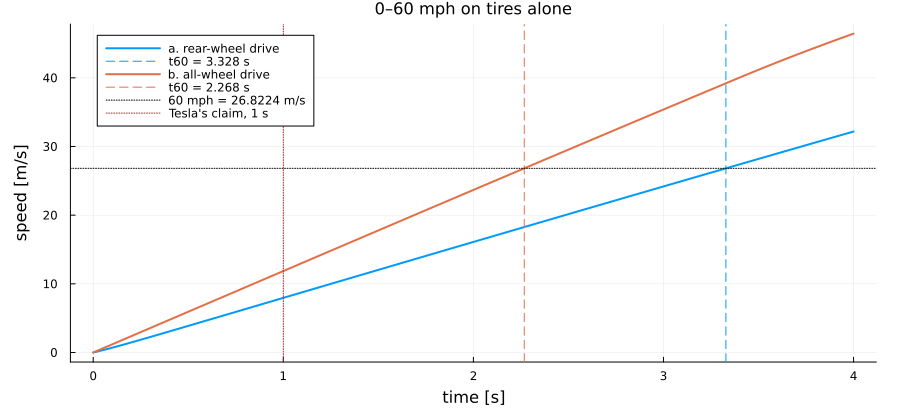

In [11]:
let ts = range(0, 4, length = 500)
    p = plot(xlabel = "time [s]", ylabel = "speed [m/s]", legend = :topleft,
        title = "0–60 mph on tires alone")
    for (run, name, c) in ((rwd, "a. rear-wheel drive", 1), (awd, "b. all-wheel drive", 2))
        plot!(p, ts, trace(run, run.model.v, ts); label = name, color = c)
        T = t60(run)
        vline!(p, [T]; color = c, ls = :dash, lw = 1, label = "t60 = $(fmt(T)) s")
    end
    hline!(p, [V60]; color = :black, ls = :dot, lw = 1, label = "60 mph = 26.8224 m/s")
    vline!(p, [1.0]; color = :firebrick, ls = :dot, lw = 1, label = "Tesla's claim, 1 s")
end

### Tire force against the grip ceiling, and the axle load

Solid lines are the tire force `F_x`; dashed lines are the ceiling `mu_A·F_z` the tire could give
at its peak. The gap is the 2 % `grip` margin plus the torque that spins up the wheel. All-wheel
drive leaves the ceiling at about 3.4 s, when the drive's power, not the tire, becomes the limit.
For rear-wheel drive, the lower panel shows the load building over the first few tenths of a
second as the pitch lag lets the transfer in.

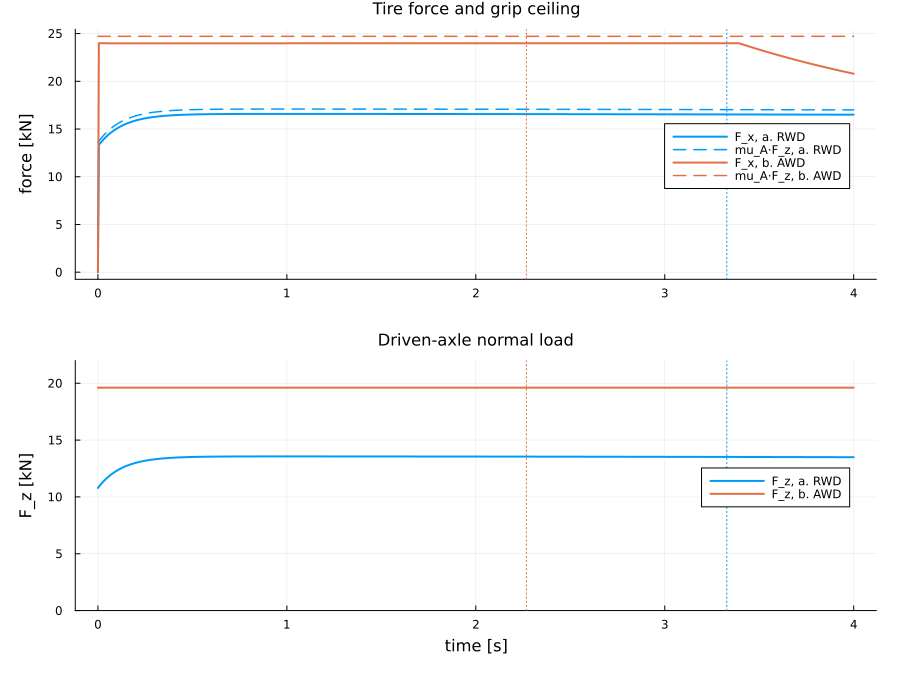

In [12]:
let ts = range(0, 4, length = 800)
    p1 = plot(title = "Tire force and grip ceiling", ylabel = "force [kN]", legend = :right)
    p2 = plot(title = "Driven-axle normal load", ylabel = "F_z [kN]", xlabel = "time [s]",
        legend = :right, ylims = (0, 22))
    for (run, name, c) in ((rwd, "a. RWD", 1), (awd, "b. AWD", 2))
        Fz = trace(run, run.model.axle.F_z, ts)
        plot!(p1, ts, trace(run, run.model.wheel.F_x, ts) ./ 1e3; color = c, label = "F_x, $name")
        plot!(p1, ts, param(run, run.model.mu_A) .* Fz ./ 1e3; color = c, ls = :dash, lw = 1.5,
            label = "mu_A·F_z, $name")
        plot!(p2, ts, Fz ./ 1e3; color = c, label = "F_z, $name")
        vline!.((p1, p2), Ref([t60(run)]); color = c, ls = :dot, lw = 1, label = "")
    end
    plot(p1, p2; layout = (2, 1), size = (900, 680))
end

### Slip

The band `0.02–0.05` is shaded; the dotted line is the adhesion peak at 0.04. The right panel
zooms on the first 20 ms: the slip reaches its working value within a few milliseconds, so the
first 0.1 s the band excludes is generous. All-wheel drive drops out of the band some time after
3.4 s, once the drive is power-limited and asks the tire for less than it can give; the band is a check
on the tire-limited launch, so section 9 measures it up to t60.

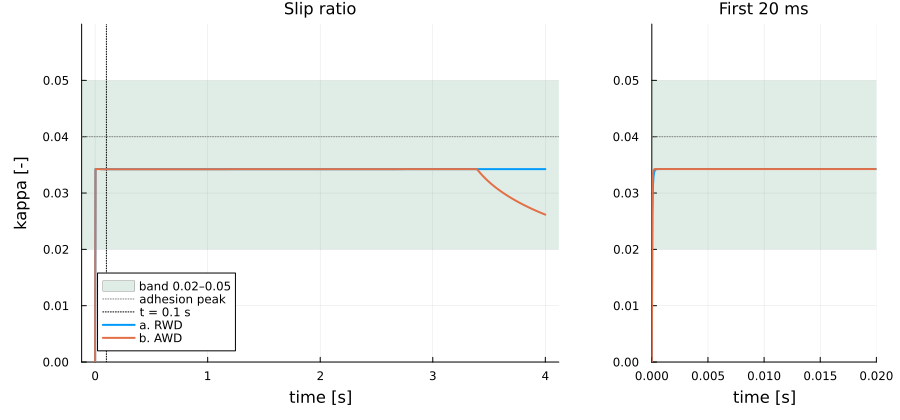

In [13]:
let ts = range(0, 4, length = 1200), tz = range(0, 0.02, length = 400)
    p = plot(title = "Slip ratio", ylabel = "kappa [-]", xlabel = "time [s]", ylims = (0, 0.06),
        legend = :bottomleft)
    z = plot(title = "First 20 ms", xlabel = "time [s]", ylims = (0, 0.06), xlims = (0, 0.02), legend = false)
    for q in (p, z)
        hspan!(q, [0.02, 0.05]; color = :seagreen, alpha = 0.15, lw = 0, label = "band 0.02–0.05")
        hline!(q, [sAdh]; color = :gray, ls = :dot, lw = 1, label = "adhesion peak")
    end
    vline!(p, [0.1]; color = :black, ls = :dot, lw = 1, label = "t = 0.1 s")
    for (run, name, c) in ((rwd, "a. RWD", 1), (awd, "b. AWD", 2))
        plot!(p, ts, trace(run, run.model.wheel.kappa, ts); color = c, label = name)
        plot!(z, tz, trace(run, run.model.wheel.kappa, tz); color = c)
    end
    plot(p, z; layout = grid(1, 2, widths = [0.68, 0.32]))
end

### The motor: which limit binds, and when

The delivered torque is the smallest of three ceilings: the traction-control request (the tire),
`T_max`, and `P_max/w`. The torque ceiling never binds in a tire-only launch: the tire asks for at
most about 8.5 kN·m of the 12 kN·m available. The power ceiling takes over for all-wheel drive at
about 40 m/s (t ≈ 3.4 s), well past 60 mph, and not within 6 s for rear-wheel drive. The second
ceiling at t60 is therefore `T_max`, not power.

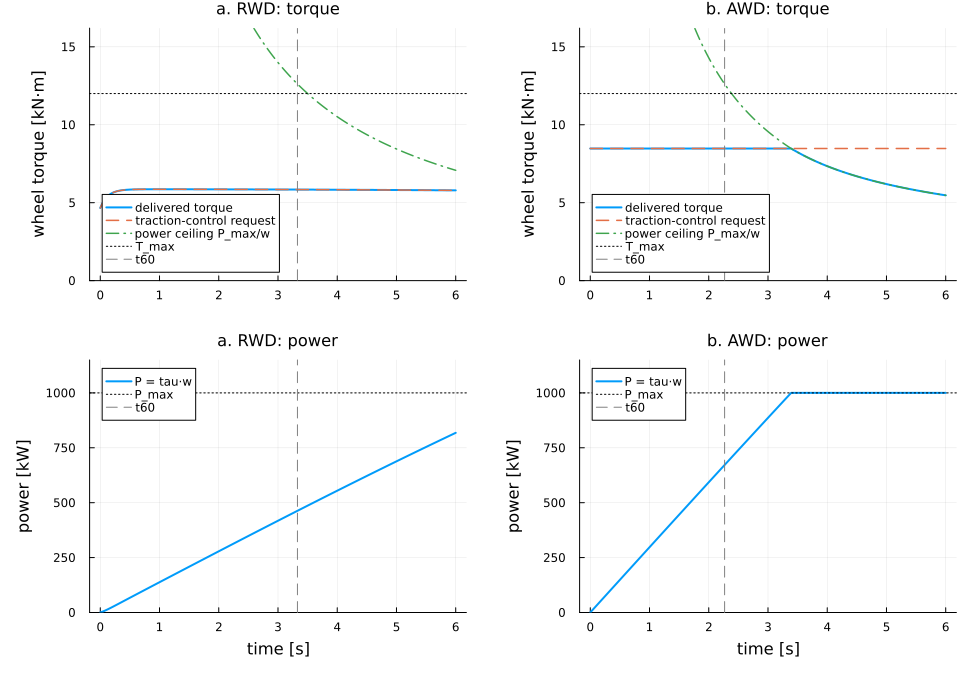

In [14]:
function motor_panels(run, name; tmax = 6.0)
    ts = range(0, tmax, length = 900)
    m = run.model
    Tmax, Pmax, weps = param(run, m.motor.T_max), param(run, m.motor.P_max), param(run, m.motor.w_eps)
    pt = plot(ts, trace(run, m.motor.tau, ts) ./ 1e3; label = "delivered torque", color = 1,
        ylabel = "wheel torque [kN·m]", title = "$name: torque", ylims = (0, 1.35Tmax / 1e3),
        legend = :bottomleft)
    plot!(pt, ts, trace(run, m.motor.tau_cmd, ts) ./ 1e3; ls = :dash, lw = 1.5, color = 2,
        label = "traction-control request")
    plot!(pt, ts, [Pmax / max(w, weps) for w in trace(run, m.motor.w, ts)] ./ 1e3; ls = :dashdot,
        lw = 1.5, color = 3, label = "power ceiling P_max/w")
    hline!(pt, [Tmax / 1e3]; color = :black, ls = :dot, lw = 1, label = "T_max")
    pp = plot(ts, trace(run, m.motor.P, ts) ./ 1e3; label = "P = tau·w", color = 1,
        ylabel = "power [kW]", xlabel = "time [s]", title = "$name: power", legend = :topleft,
        ylims = (0, 1150))
    hline!(pp, [Pmax / 1e3]; color = :black, ls = :dot, lw = 1, label = "P_max")
    T = t60(run)
    vline!.((pt, pp), Ref([T]); color = :gray, ls = :dash, lw = 1, label = "t60")
    return pt, pp
end

power_onset(run) = crossing(run, run.model.motor.P, 0.999param(run, run.model.motor.P_max))

let a = motor_panels(rwd, "a. RWD"), b = motor_panels(awd, "b. AWD")
    plot(a[1], b[1], a[2], b[2]; layout = (2, 2), size = (980, 680))
end

In [15]:
for (run, name) in ((rwd, "a. RWD"), (awd, "b. AWD"))
    T = power_onset(run)
    onset = isinf(T) ? "never within 6 s" : "at t = $(fmt(T)) s, v = $(fmt(at(run, run.model.v, T); d = 1)) m/s"
    b = binding_limit(run, t60(run))
    println(rpad(name, 8), "binding at t60: ", b.limit, " (next: ", b.next, ", ", fmt(100b.margin; d = 0),
        " % higher);  power limit binds ", onset)
end

a. RWD  binding at t60: 

tire (next: torque, 105 % higher);  power limit binds never within 6 s
b. AWD  binding at t60: tire (next: torque, 42 % higher);  power limit binds at t = 3.387 s, v = 39.9 m/s


## 5. Independent checks on signs and balances

The brief asks for the sign conventions to be checked against the standard library. The verdict
is in section 10; these residuals are the numerical half of it. If any sign were wrong, one of
these would be of the order of the forces themselves, not of the solver tolerance.

- Body: `m·a = F_x − F_drag − F_roll`. Drag and rolling resistance are flows into their elements,
  so positive values leave the body node.
- Wheel shaft: `J_w·alpha = tau − r·F_x`.
- One shaft: motor, inertia and tire must report the same angular speed.
- Axle load: rear-wheel drive must gain load as the car accelerates.

In [16]:
let rows = String[]
    for (run, name) in ((rwd, "a. RWD"), (awd, "b. AWD"))
        m = run.model
        ts = range(0.01, 6, length = 600)
        mv, J, r = param(run, m.m), param(run, m.J_w), param(run, m.radius)
        body = maximum(abs(mv * at(run, m.axle.a, t) - (at(run, m.wheel.F_x, t) - at(run, m.body.drag.f, t) -
                                                        at(run, m.body.rolling.f, t))) for t in ts)
        shaft = maximum(abs(J * at(run, m.wheel_inertia.a, t) - (at(run, m.motor.tau, t) - r * at(run, m.wheel.F_x, t)))
                        for t in ts)
        speeds = maximum(max(abs(at(run, m.motor.w, t) - at(run, m.wheel.omega, t)),
                             abs(at(run, m.motor.w, t) - at(run, m.wheel_inertia.w, t))) for t in ts)
        Fx_min = minimum(at(run, m.wheel.F_x, t) for t in ts)
        dFz = at(run, m.axle.F_z, t60(run)) - at(run, m.axle.F_z, 0.0)
        push!(rows, "$name  |m·a − ΣF| ≤ $(@sprintf("%.1e", body)) N   |J·alpha − (tau − r·F_x)| ≤ $(@sprintf("%.1e", shaft)) N·m" *
                    "   |Δw| ≤ $(@sprintf("%.1e", speeds)) rad/s   min F_x = $(fmt(Fx_min / 1e3; d = 2)) kN   ΔF_z(0→t60) = $(fmt(dFz / 1e3; d = 2)) kN")
    end
    foreach(println, rows)
end

a. RWD  |m·a − ΣF| ≤ 3.6e-12 N   |J·alpha − (tau − r·F_x)| ≤ 1.8e-12 N·m   |Δw| ≤ 0.0e+00 rad/s   min F_x = 13.45 kN   ΔF_z(0→t60) = 2.73 kN


b. AWD  |m·a − ΣF| ≤ 3.6e-12 N   |J·alpha − (tau − r·F_x)| ≤ 1.8e-12 N·m   |Δw| ≤ 0.0e+00 rad/s   min F_x = 15.50 kN   ΔF_z(0→t60) = 0.00 kN


## 6. Mass sweep — scenario c

Tesla has not published the mass; estimates run from under 1,700 kg to about 2,350 kg. A
tire-limited launch should not care: weight raises the available tire force in proportion to the
mass it has to accelerate. The three published estimates are scenario c; the finer sweep around
them draws the curve. The residual slope comes from what does not scale with mass: `J_w` and
`CdA` are fixed, so they cost a light car proportionally more.

RWD  m = 1700

 kg   t60 = 3.340 s
RWD  m = 2000 kg   t60 = 3.328 s
RWD  m = 2350 kg   t60 = 3.319 s
spread (max − min)/t60(2000 kg) = 0.62 %


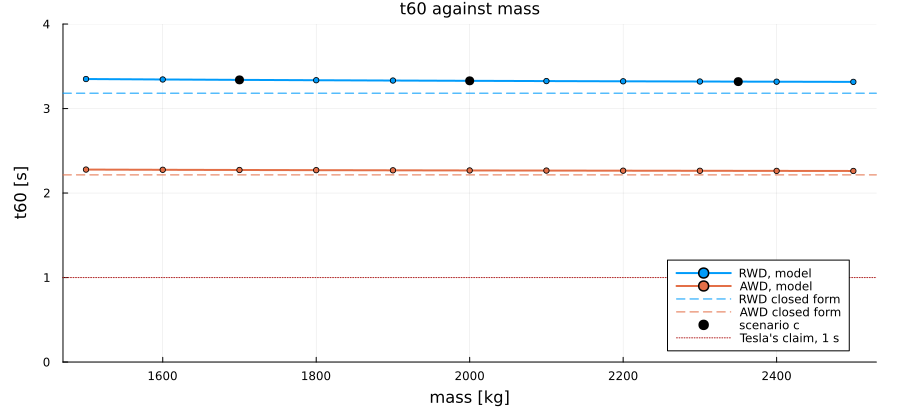

In [17]:
masses_c = [1700.0, 2000.0, 2350.0]
runs_c = [launch(m = x) for x in masses_c]
t60_c = t60.(runs_c)
spread_c = (maximum(t60_c) - minimum(t60_c)) / t60_c[2]

sweep = 1500.0:100.0:2500.0
t60_sweep_rwd = [t60(launch(m = x)) for x in sweep]
t60_sweep_awd = [t60(launch(m = x, share = 1.0, h_over_L = 0.0)) for x in sweep]

for (x, T) in zip(masses_c, t60_c)
    println("RWD  m = ", Int(x), " kg   t60 = ", fmt(T), " s")
end
println("spread (max − min)/t60(2000 kg) = ", fmt(100spread_c; d = 2), " %")

let p = plot(xlabel = "mass [kg]", ylabel = "t60 [s]", title = "t60 against mass",
        legend = :bottomright, ylims = (0, 4))
    plot!(p, sweep, t60_sweep_rwd; color = 1, marker = :circle, ms = 3, label = "RWD, model")
    plot!(p, sweep, t60_sweep_awd; color = 2, marker = :circle, ms = 3, label = "AWD, model")
    hline!(p, [t60_rwd_cf]; color = 1, ls = :dash, lw = 1, label = "RWD closed form")
    hline!(p, [t60_awd_cf]; color = 2, ls = :dash, lw = 1, label = "AWD closed form")
    scatter!(p, masses_c, t60_c; color = :black, ms = 5, label = "scenario c")
    hline!(p, [1.0]; color = :firebrick, ls = :dot, lw = 1, label = "Tesla's claim, 1 s")
end

## 7. Stickier tires — scenario d

All-wheel drive with `mu_A = 1.5`, a value a road-legal tire does not reach but a fresh slick can.
Even then the car is far from one second, because `t60 ≥ v60/(mu·g)` and `mu` would have to be
about 2.8 for one second.

In [18]:
awd15 = launch(share = 1.0, h_over_L = 0.0, mu_A = 1.5)
t60_awd15_cf = V60 / (grip * 1.5 * g)
println("AWD, mu_A = 1.5:  closed form ", fmt(t60_awd15_cf), " s,  model ", fmt(t60(awd15)), " s")
println("mu needed for 1.0 s on tires:  v60/(grip·g·1 s) = ", fmt(V60 / (grip * g * 1.0); d = 2))
b = binding_limit(awd15, t60(awd15))
println("binding at t60: ", b.limit, "; next: ", b.next, ", only ", fmt(100b.margin; d = 0), " % above the request")
r, Tmax, Pmax = param(awd, M.radius), param(awd, M.T_max), param(awd, M.P_max)
println("mu_A at which T_max binds from the start:     T_max/(grip·m·g·r)                 = ",
        fmt(Tmax / (grip * mass * g * r); d = 2))
println("mu_A at which P_max binds before 60 mph:      P_max/(grip·m·g·v60·(1 + kappa))  = ",
        fmt(Pmax / (grip * mass * g * V60 * (1 + kappa_cf)); d = 2))

AWD, mu_A = 1.5:  closed form 1.861

 s,  model 1.901 s
mu needed for 1.0 s on tires:  v60/(grip·g·1 s) = 2.79
binding at t60: tire; next: torque, only 19 % above the request
mu_A at which T_max binds from the start:     T_max/(grip·m·g·r)                 = 1.78
mu_A at which P_max binds before 60 mph:      P_max/(grip·m·g·v60·(1 + kappa))  = 1.87


## 8. Pitch lag — scenario e

`T_pitch` is not a parameter of `RoadsterLaunchTransient`, so it cannot be passed as a keyword.
It is a tunable parameter of the compiled system (`axle.T_pitch`), so `rerun` sets it with
`remake` on the analysis's own `ODEProblem` and re-solves. That changes nothing else: the
`share` and `h_over_L` the analysis set stay in place, which the AWD row confirms.

`0.01 s` is added as a near-instantaneous reference: it is the closest the model gets to the
closed form's assumption.

RWD  T_pitch = 0.01 

 s   t60 = 3.305 s   (-0.70 %)
RWD  T_pitch = 0.05  s   t60 = 3.315 s   (-0.39 %)
RWD  T_pitch = 0.1   s   t60 = 3.328 s   (-0.00 %)
RWD  T_pitch = 0.2   s   t60 = 3.354 s   (+0.78 %)
AWD  T_pitch = 0.2   s   t60 = 2.268 s   (no transfer, so no effect: Δ = 2.0e-07 s)


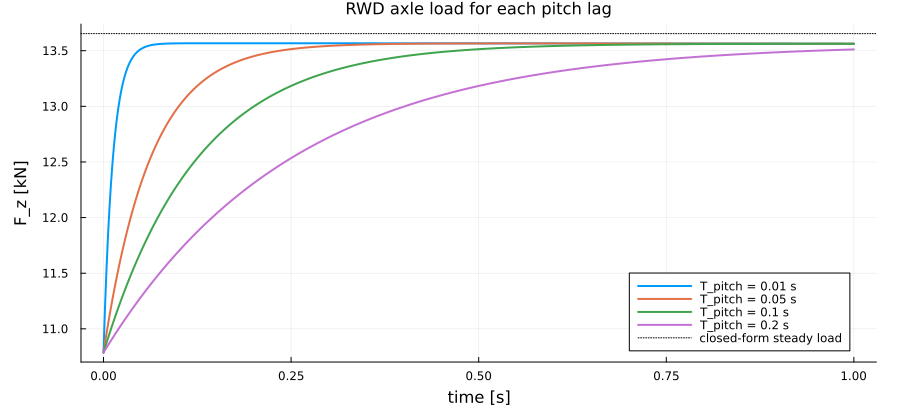

In [19]:
pitch_values = [0.01, 0.05, 0.1, 0.2]
pitch_runs = [rerun(rwd, rwd.model.axle.T_pitch => T) for T in pitch_values]
t60_pitch = t60.(pitch_runs)
for (T, t) in zip(pitch_values, t60_pitch)
    println("RWD  T_pitch = ", rpad(T, 5), " s   t60 = ", fmt(t), " s   (", @sprintf("%+.2f", 100(t / t60(rwd) - 1)), " %)")
end
awd_pitch = rerun(awd, awd.model.axle.T_pitch => 0.2)
println("AWD  T_pitch = 0.2   s   t60 = ", fmt(t60(awd_pitch)), " s   (no transfer, so no effect: Δ = ",
    @sprintf("%.1e", t60(awd_pitch) - t60(awd)), " s)")

let ts = range(0, 1.0, length = 500)
    p = plot(title = "RWD axle load for each pitch lag", xlabel = "time [s]", ylabel = "F_z [kN]",
        legend = :bottomright)
    for (T, run, c) in zip(pitch_values, pitch_runs, 1:4)
        plot!(p, ts, trace(run, run.model.axle.F_z, ts) ./ 1e3; color = c, label = "T_pitch = $T s")
    end
    hline!(p, [share * mass * g * (1 + a_rwd_cf * hL / share) / 1e3]; color = :black, ls = :dot, lw = 1,
        label = "closed-form steady load")
end

### Where the gap to the closed form goes

The model is 2–5 % slower than the closed forms. Switching off the four effects the closed forms
leave out (drag, rolling resistance, wheel inertia, pitch lag) and adding them back one at a time
shows whether that gap is fully explained, or whether something else is hiding in it. "Off" is
`CdA = 0`, `f_r = 0`, `J_w = 0.001 kg·m²`, `T_pitch = 0.001 s`.

In [20]:
function effects_off(run)
    m = run.model
    return [:drag => (m.CdA => 0.0), :rolling => (m.body.f_r => 0.0),
            :inertia => (m.J_w => 1e-3), :pitch => (m.axle.T_pitch => 1e-3)]
end

function gap_table(run, closed)
    off = effects_off(run)
    rows = [["closed form", fmt(closed), "—"]]
    for k in 0:length(off)
        on = first.(off[1:k])
        T = t60(rerun(run, last.(off[k+1:end])...))
        label = k == 0 ? "model, all four off" : "+ " * string(on[end])
        push!(rows, [label, fmt(T; d = 4), @sprintf("%+.2f %%", 100(T / closed - 1))])
    end
    return rows
end

display(Markdown.parse("**a. Rear-wheel drive**"))
display(mdtable(["", "t60 [s]", "vs closed form"], gap_table(rwd, t60_rwd_cf)))
display(Markdown.parse("**b. All-wheel drive**"))
display(mdtable(["", "t60 [s]", "vs closed form"], gap_table(awd, t60_awd_cf)))

**a. Rear-wheel drive**


|                     | t60 [s] | vs closed form |
|:------------------- |:------- |:-------------- |
| closed form         | 3.182   | —              |
| model, all four off | 3.1822  | +0.01 %        |
| + drag              | 3.2031  | +0.66 %        |
| + rolling           | 3.2611  | +2.49 %        |
| + inertia           | 3.3029  | +3.80 %        |
| + pitch             | 3.3284  | +4.60 %        |


**b. All-wheel drive**


|                     | t60 [s] | vs closed form |
|:------------------- |:------- |:-------------- |
| closed form         | 2.215   | —              |
| model, all four off | 2.2150  | +0.00 %        |
| + drag              | 2.2230  | +0.36 %        |
| + rolling           | 2.2449  | +1.35 %        |
| + inertia           | 2.2676  | +2.37 %        |
| + pitch             | 2.2676  | +2.37 %        |


With all four effects off, both models land on their closed form to within a few parts in ten
thousand, so the equations are what the closed forms say they are. Rolling resistance and wheel
inertia carry most of the gap; drag is small below 27 m/s, and the pitch lag costs about 0.8 % for
rear-wheel drive and nothing for all-wheel drive.

### Wheel inertia is not compensated

The traction control requests `grip·mu_A·F_z·r` and nothing more, so the torque that spins up the
wheel, `J_w·alpha ≈ J_w·a/r`, comes off the tire force rather than out of the motor's spare
torque. Each kg·m² of `J_w` therefore acts like `1/r² ≈ 8 kg` of extra car that the tire must
push. The default 2.4 kg·m² is about right for two driven road wheels, but the motors' rotors are
lumped in the same number, and a rotor spinning 8.5 times faster counts `8.5² = 72` times. Two
rotors of an assumed 0.03–0.05 kg·m² each would add 4–7 kg·m², putting `J_w` near 7–10 kg·m²;
the sweep brackets that.

In [21]:
Jw_values = [2.4, 5.0, 10.0]
rows = map(Jw_values) do J
    Tr = t60(rerun(rwd, rwd.model.J_w => J))
    Ta = t60(rerun(awd, awd.model.J_w => J))
    [fmt(J; d = 1), fmt(J / 0.35^2; d = 0), fmt(Ta), (2.20 <= Ta <= 2.35 ? "pass" : "**MISS**"),
     fmt(Tr), (3.15 <= Tr <= 3.45 ? "pass" : "**MISS**")]
end
mdtable(["J_w [kg·m²]", "J_w/r² [kg]", "AWD t60 [s]", "2.20–2.35", "RWD t60 [s]", "3.15–3.45"], rows)

| J_w [kg·m²] | J_w/r² [kg] | AWD t60 [s] | 2.20–2.35 | RWD t60 [s] | 3.15–3.45 |
|:----------- |:----------- |:----------- |:--------- |:----------- |:--------- |
| 2.4         | 20          | 2.268       | pass      | 3.328       | pass      |
| 5.0         | 41          | 2.292       | pass      | 3.373       | pass      |
| 10.0        | 82          | 2.339       | pass      | 3.459       | **MISS**  |


### The traction control does not survive the solver's default tolerances

`RoadsterLaunchTransient` pins `abstol = 1e-8`, `reltol = 1e-6`. Here is the same compiled problem
solved with the solver's defaults instead, with nothing else changed.

default tolerances:  t60 = 4.275

 s  (pinned: 3.328 s)
kappa passes the 0.04 peak at t = 1.0e-04 s and peaks at 23.4
F_x / F_z at t = 2 s: 1.000  (mu_S = 1.0, grip·mu_A = 1.235)


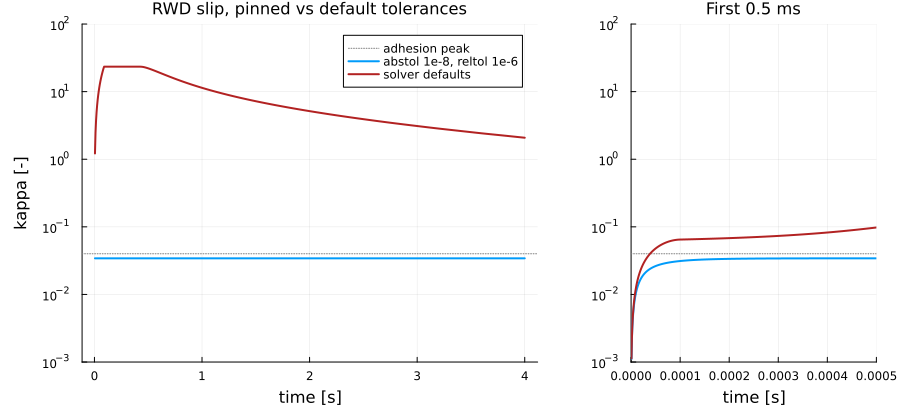

In [22]:
loose = (sol = solve(remake(rwd.sol.prob)), model = rwd.model)
k_loose = loose.sol[loose.model.wheel.kappa]
first_over = loose.sol.t[findfirst(>(sAdh), k_loose)]
println("default tolerances:  t60 = ", fmt(t60(loose)), " s  (pinned: ", fmt(t60(rwd)), " s)")
println("kappa passes the 0.04 peak at t = ", @sprintf("%.1e", first_over), " s and peaks at ", fmt(maximum(k_loose); d = 1))
println("F_x / F_z at t = 2 s: ", fmt(at(loose, loose.model.wheel.F_x, 2.0) / at(loose, loose.model.axle.F_z, 2.0)),
        "  (mu_S = ", param(loose, loose.model.mu_S), ", grip·mu_A = ", fmt(grip * mu), ")")

let ts = range(0, 4, length = 800), tz = range(0, 5e-4, length = 600)
    p = plot(title = "RWD slip, pinned vs default tolerances", xlabel = "time [s]", ylabel = "kappa [-]",
        yscale = :log10, ylims = (1e-3, 100), legend = :topright)
    z = plot(title = "First 0.5 ms", xlabel = "time [s]", yscale = :log10, ylims = (1e-3, 100),
        xlims = (0, 5e-4), legend = false)
    for q in (p, z)
        hline!(q, [sAdh]; color = :gray, ls = :dot, lw = 1, label = "adhesion peak")
    end
    for (run, name, c) in ((rwd, "abstol 1e-8, reltol 1e-6", 1), (loose, "solver defaults", :firebrick))
        plot!(p, ts[2:end], max.(trace(run, run.model.wheel.kappa, ts[2:end]), 1e-3); color = c, label = name)
        plot!(z, tz[2:end], max.(trace(run, run.model.wheel.kappa, tz[2:end]), 1e-3); color = c)
    end
    plot(p, z; layout = grid(1, 2, widths = [0.65, 0.35]))
end

At standstill the slip is `omega·r / v_eps`, and the motor's full request hits a 2.4 kg·m² wheel
that the tire has not yet started to resist. The slip climbs through the 0.04 peak within the first
0.1 ms. A tight solver takes steps small enough to let the tire force catch the wheel on the
rising branch. A loose one steps over the peak, and from there nothing brings it back: the request
`grip·mu_A·F_z·r = 1.235·F_z·r` exceeds what the sliding tire can return, `mu_S·F_z·r = 1.0·F_z·r`,
and the controller never looks at slip. The wheel spins for the whole run while the car accelerates
on sliding friction, and the "result" is 4.27 s. That number is not physics; it is a step-size
artifact of an open-loop controller.

The shipped analysis is correct, and so are the snapshot tests that call it. But the correctness
hangs on the tolerance, not the model, and a student who solves the problem directly, or edits the
analysis's tolerances, gets a second answer from the same equations.

## 9. Acceptance table

Every row of the task 1 acceptance table. Closed forms come from section 3. `t60` comes from the
dense interpolant. Slip is sampled at 2,000 points on `[0.1 s, t60]` for each drive layout.

In [23]:
function slip_range(run; t0 = 0.1, t1 = t60(run))
    k = trace(run, run.model.wheel.kappa, range(t0, t1, length = 2000))
    return extrema(k)
end
verdict(ok) = ok ? "pass" : "**MISS**"

T_awd, T_rwd = t60(awd), t60(rwd)
P60 = at(awd, awd.model.motor.P, T_awd)
k_rwd, k_awd = slip_range(rwd), slip_range(awd)

acceptance = [
    ["All-wheel drive t60", "v60/(grip·mu_A·g) = $(fmt(t60_awd_cf)) s", "2.20–2.35 s", "$(fmt(T_awd)) s",
     verdict(2.20 <= T_awd <= 2.35)],
    ["Rear-wheel drive t60", "a/g = $(fmt(a_rwd_cf)) → $(fmt(t60_rwd_cf)) s", "3.15–3.45 s", "$(fmt(T_rwd)) s",
     verdict(3.15 <= T_rwd <= 3.45)],
    ["Mass sweep 1,700–2,350 kg (RWD)", "mass-independent: spread 0 %", "spread < 3 %",
     "$(join(fmt.(t60_c), " / ")) s → $(fmt(100spread_c; d = 2)) %", verdict(spread_c < 0.03)],
    ["Drive power at 60 mph, AWD", "$(fmt(F_awd_cf / 1e3; d = 1)) kN × $(fmt(V60; d = 2)) m/s = $(fmt(P_awd_cf / 1e3; d = 0)) kW",
     "< 1 MW (tire limits, not power)", "$(fmt(P60 / 1e3; d = 1)) kW; binding: $(binding_limit(awd, T_awd).limit)",
     verdict(P60 < param(awd, awd.model.P_max) && binding_limit(awd, T_awd).limit == :tire)],
    ["Slip, RWD, 0.1 s to t60", "held just below the peak: kappa = $(fmt(kappa_cf; d = 4))", "0.02–0.05",
     "$(fmt(k_rwd[1]; d = 4))–$(fmt(k_rwd[2]; d = 4))", verdict(0.02 <= k_rwd[1] && k_rwd[2] <= 0.05)],
    ["Slip, AWD, 0.1 s to t60", "held just below the peak: kappa = $(fmt(kappa_cf; d = 4))", "0.02–0.05",
     "$(fmt(k_awd[1]; d = 4))–$(fmt(k_awd[2]; d = 4))", verdict(0.02 <= k_awd[1] && k_awd[2] <= 0.05)],
]
mdtable(["Check", "Closed form", "Band", "Measured", "Result"], acceptance)

| Check                           | Closed form                              | Band                            | Measured                         | Result |
|:------------------------------- |:---------------------------------------- |:------------------------------- |:-------------------------------- |:------ |
| All-wheel drive t60             | v60/(grip·mu_A·g) = 2.215 s              | 2.20–2.35 s                     | 2.268 s                          | pass   |
| Rear-wheel drive t60            | a/g = 0.860 → 3.182 s                    | 3.15–3.45 s                     | 3.328 s                          | pass   |
| Mass sweep 1,700–2,350 kg (RWD) | mass-independent: spread 0 %             | spread < 3 %                    | 3.340 / 3.328 / 3.319 s → 0.62 % | pass   |
| Drive power at 60 mph, AWD      | 24.2 kN × 26.82 m/s = 650 kW             | < 1 MW (tire limits, not power) | 671.8 kW; binding: tire          | pass   |
| Slip, RWD, 0.1 s to t60         | held just below the peak: kappa = 0.0353 | 0.02–0.05                       | 0.0342–0.0342                    | pass   |
| Slip, AWD, 0.1 s to t60         | held just below the peak: kappa = 0.0353 | 0.02–0.05                       | 0.0342–0.0342                    | pass   |


Notes on the table:

- The measured drive power exceeds `F·v60` by about 3.4 %, and the closed form with the
  `(1 + kappa)` factor of section 3 accounts for almost all of it: the motor turns the tread
  faster than the car moves.
- Measured slip sits slightly below the closed-form `kappa` because the wheel inertia takes about
  1 % of the requested torque (section 8).
- Over the whole 6 s run, all-wheel drive slip falls to about 0.018 once the power limit binds at
  about 3.4 s. That is outside the band but is not a failure: the band describes a tire-limited
  launch, and by then the tire is no longer the limit. The brief's wording ("after the first
  0.1 s") does not say where the window ends; measured to t60, it passes.

In [24]:
let k = slip_range(awd; t1 = 6.0)
    println("AWD slip over [0.1 s, 6 s]: ", fmt(k[1]; d = 4), "–", fmt(k[2]; d = 4))
end

AWD slip over [0.1 s, 6 s]: 0.0179–0.0343


## Scenario table

In [25]:
scenarios = [
    ("a. RWD defaults", rwd, t60_rwd_cf),
    ("b. AWD", awd, t60_awd_cf),
    ("c. RWD, m = 1,700 kg", runs_c[1], t60_rwd_cf),
    ("c. RWD, m = 2,000 kg", runs_c[2], t60_rwd_cf),
    ("c. RWD, m = 2,350 kg", runs_c[3], t60_rwd_cf),
    ("d. AWD, mu_A = 1.5", awd15, t60_awd15_cf),
    ("e. RWD, T_pitch = 0.05 s", pitch_runs[2], t60_rwd_cf),
    ("e. RWD, T_pitch = 0.2 s", pitch_runs[4], t60_rwd_cf),
]
rows = map(scenarios) do (name, run, closed)
    T = t60(run)
    b = binding_limit(run, T)
    [name, fmt(T), fmt(closed), fmt(peak_g(run, T)), fmt(at(run, run.model.axle.F_z, 0.0) / 1e3; d = 2),
     fmt(at(run, run.model.axle.F_z, T) / 1e3; d = 2), "$(b.limit) (next: $(b.next), +$(fmt(100b.margin; d = 0)) %)"]
end
mdtable(["Scenario", "t60 [s]", "closed form [s]", "peak a [g]", "F_z(0) [kN]", "F_z(t60) [kN]",
         "binding at t60"], rows)

| Scenario                 | t60 [s] | closed form [s] | peak a [g] | F_z(0) [kN] | F_z(t60) [kN] | binding at t60              |
|:------------------------ |:------- |:--------------- |:---------- |:----------- |:------------- |:--------------------------- |
| a. RWD defaults          | 3.328   | 3.182           | 0.833      | 10.79       | 13.52         | tire (next: torque, +105 %) |
| b. AWD                   | 2.268   | 2.215           | 1.211      | 19.61       | 19.61         | tire (next: torque, +42 %)  |
| c. RWD, m = 1,700 kg     | 3.340   | 3.182           | 0.831      | 9.17        | 11.48         | tire (next: torque, +142 %) |
| c. RWD, m = 2,000 kg     | 3.328   | 3.182           | 0.833      | 10.79       | 13.52         | tire (next: torque, +105 %) |
| c. RWD, m = 2,350 kg     | 3.319   | 3.182           | 0.834      | 12.68       | 15.90         | tire (next: torque, +75 %)  |
| d. AWD, mu_A = 1.5       | 1.901   | 1.861           | 1.444      | 19.61       | 19.61         | tire (next: torque, +19 %)  |
| e. RWD, T_pitch = 0.05 s | 3.315   | 3.182           | 0.833      | 10.79       | 13.51         | tire (next: torque, +105 %) |
| e. RWD, T_pitch = 0.2 s  | 3.354   | 3.182           | 0.830      | 10.79       | 13.52         | tire (next: torque, +105 %) |


"Next" names the second-lowest of the three ceilings (tire request, `T_max`, `P_max/w`) at t60 and
how far above the binding one it sits. The tire binds in every scenario, and the next ceiling is
always the 12 kN·m torque limit, not the 1 MW. Scenario d comes closest: with `mu_A = 1.5` the
torque ceiling is 19 % above the request, and section 7 shows that `T_max` would bind from the
start above `mu_A ≈ 1.78`, before power would matter at 60 mph (`mu_A ≈ 1.87`). That is the
handover to task 2, where suction raises the effective `mu_A·F_z` and the torque ceiling becomes
the limit.

## 10. Review verdicts

### Sign conventions — kept

Read against `agent_resources/stdlib_reference/`:

- **Motor.** `RotationalComponents/Interfaces/PartialTorque.dyad` and
  `Sources/ConstantTorque.dyad` define the accelerating torque as `tau = -spline.tau`;
  `Sources/TorqueSource.dyad` writes the same as `spline.tau = -tau`. `PowerLimitedMotor` extends
  `PartialTorque` and uses exactly `tau = -spline.tau`. Its support goes to a `Fixed`, and the
  `PartialElementaryOneSplineAndSupport` reaction `support.tau = -spline.tau` is inherited.
- **Wheel.** `Dyad/Spline.dyad` and `Dyad/Flange.dyad` make torque and force flows, positive
  into the component. `Components/Inertia.dyad` has `J·a = spline_a.tau + spline_b.tau`, and
  `TranslationalComponents/Components/Mass.dyad` has `m·a = flange_a.f + flange_b.f`. The tire
  writes `flange.f = -F_x`, so the body node receives `+F_x`, and
  `0 = spline.tau + r·flange.f` gives `spline.tau = r·F_x` flowing into the tire, which is the
  reaction torque `−r·F_x` on the wheel inertia. Both are the stdlib's flow sign.
- **Axle load.** `flange.f = 0` makes it a sensor, and `+m·a·h/L` loads the rear axle under
  acceleration, which is correct for both layouts the session uses. A front-drive car would need
  a negative `h_over_L`; the docstring does not say so, but no task uses one.

Section 5 confirms it numerically: the body and shaft balances close to solver precision, every
shaft reports one speed, `F_x` is never negative, and rear-wheel drive gains load. **If a sign
were wrong**, a student would see the car pushed backward by the tire, or the wheel braked by its
own motor, or the rear axle unloading under acceleration and the RWD launch getting *faster* than
the closed form instead of slower.

### Traction control reads `F_z` directly — should change

As a teaching idealization, "perfect traction control" is the right question to ask: it isolates
the tire limit from controller design, and the closed forms in section 3 are exactly its
predictions, which the model reproduces once the side effects are off. The problem is the
implementation. It is open loop on `F_z`: nothing in it looks at slip, so it has no way back if
the tire passes its peak, and with `grip·mu_A = 1.235 > mu_S = 1.0` it can never get back on its
own. Section 8 shows the consequence: the same model at the solver's default tolerances spins
the wheel in the first tenth of a millisecond and reports 4.27 s. The analysis's tight tolerances
hide this; they do not cure it. **A student would see** a launch slower than the closed form by
a third, a slip ratio above 20, and a sliding tire, from a model they were told has ideal traction
control, as soon as they solve it with default settings or change the tolerances. Recommendation
for whoever owns the model: keep the `F_z` feedforward, and add slip feedback that cuts the
request when `kappa` exceeds a target below `sAdhesion`, the same idea lecture 1's notebook 10
builds. That makes the result independent of the step size, and makes "ideal" mean "holds the
peak" rather than "never leaves it by luck".

### `T_pitch = 0.1 s` — kept

Halving it to 0.05 s or doubling it to 0.2 s moves the rear-wheel drive t60 by well under 1 %,
and even a near-instant 0.01 s only recovers about 0.7 %. All stay inside the band. A body
pitching in about a tenth of a second is in the right range for a stiff sports car; the exact
value does not matter to the verdict, which is what a reduced-order lag should achieve. For
all-wheel drive it has no effect at all, because `h_over_L = 0`. Its real job is numerical: it
stops the solver from solving the load equation for the acceleration. **If it were wrong**, say
2 s, a student would see the rear load building slowly through most of the launch and t60 drift
toward the no-transfer value, `v60/(grip·mu_A·share·g)` = 4.0 s.

### `J_w = 2.4 kg·m²`, `mu_S = 1.0`, `CdA = 0.6 m²` — kept, with one caveat on `J_w`

- **`J_w`.** 2.4 kg·m² is about right for two driven road wheels, and its cost is about 1 % of
  t60. The caveat is that the number also has to carry the motors' rotors, reflected through the
  reduction by `8.5² = 72`, and the traction control does not pay for wheel inertia out of the
  motor's spare torque (section 8). With two rotors of an assumed 0.03–0.05 kg·m² each, `J_w` is
  about 7–10 kg·m², and at 10 kg·m² rear-wheel drive misses its band at about 3.46 s. The docstring should
  say that `J_w` is wheels plus reflected rotors. The value can stay for the session, because the
  verdict (no, by a factor of three) does not depend on it.
- **`mu_S = 1.0`.** A sliding-to-peak ratio of 0.79 is typical for a performance tire. It plays
  no role while the tire stays below the peak, which in the shipped analysis it does throughout.
  It matters only in the failure of section 8, where it sets how slow the sliding launch is.
- **`CdA = 0.6 m²`.** About `Cd ≈ 0.3` on 2 m² of frontal area, a plausible sports-car value.
  At 60 mph drag is 0.26 kN against 17–24 kN of tire force, so the launch barely notices it.

**If one of them were wrong** by a plausible amount, a student would see t60 shift by a few
percent, never enough to change the answer; only a `J_w` many times too large would pull the
rear-wheel drive result out of its band.

### Rolling resistance ignores downforce — kept for task 1, must change for task 2

`VehicleBody` passes `fWeight = m·g` to `TranslationalComponents.Components.RollingResistance`,
whose `fWeight` is a parameter, not a signal. In task 1 there is no downforce
(`no_downforce.k = 0`), so this is exact here. In task 2, 4,700 kg of suction adds
`f_r·D·g ≈ 0.55 kN` of rolling resistance, more than twice the 0.24 kN that `m·g` gives. That
is still small against the roughly 34 kN the drive's torque ceiling puts through the tires, but it is the term
that makes a fan pay at the road, and the brief already flags it. **If it stays as it is**,
students in task 2 would see a slightly-too-fast suction launch and, more to the point, would
read a model that claims downforce costs nothing at the tire.

### Motor and reduction lumped into one wheel-torque source — kept, with the inertia caveat

For a 1D launch the reduction only rescales torque and speed, so a source referred to the wheels
gives the same tire force and power. What the lumping hides:

1. **Reflected rotor inertia**, covered under `J_w` above. This is the only one that changes a
   task 1 number.
2. **Motor speed.** At 60 mph the motor turns at about 6,400 rpm, which is fine. At the claimed
   top speed of over 230 mph it would need about 24,000 rpm, and nothing in the model limits it.
   Not a task 1 issue.
3. **Driveline losses.** `P_max` is at the wheels, so the 1 MW is a wheel figure. Two or three
   percent of gear loss would not change which limit binds at 60 mph.

**If students needed to see the reduction**, the lumped model would hide the most teachable of
these: that a small, fast rotor can matter as much as four big wheels. That is worth one sentence
in the session, not a separate component.

## What this bought us

On its tires alone, the Roadster cannot reach 60 mph in one second: about 2.27 s with all-wheel
drive and about 3.33 s with the rear-wheel drive Tesla describes, set by `mu_A·g` and weight
transfer, with the 1 MW drive in reserve. The model does what its closed forms say once the small
effects are accounted for. Before the session builds on it, the traction control needs slip
feedback, and `J_w` should be documented as wheels plus reflected rotors.

Next: task 2, the suction fan, which moves the limit from the tire to the drive's torque.